In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  StandardScaler
from sklearn.metrics import classification_report,accuracy_score,precision_score,r2_score


# **Linking Kaggle with Colab**

In [3]:
import os
os.environ['KAGGLE_API_TOKEN'] = "KGAT_1d118091dba8bab79ca9a32162ff24de"

In [4]:
!kaggle datasets download -d stefanoleone992/fifa-23-complete-player-dataset

Dataset URL: https://www.kaggle.com/datasets/stefanoleone992/fifa-23-complete-player-dataset
License(s): CC0-1.0
100% 1.58G/1.58G [00:13<00:00, 127MB/s]



In [5]:
!unzip fifa-23-complete-player-dataset.zip male_players.csv

Archive:  fifa-23-complete-player-dataset.zip
  inflating: male_players.csv        


# **Read ELdata**

In [6]:
df = pd.read_csv('male_players.csv', nrows=10)
df.head()

,player_id,player_url,fifa_version,fifa_update,fifa_update_date,short_name,long_name,player_positions,overall,potential,...,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk,player_face_url
0,158023,/player/158023/lionel-messi/230009,23,9,2023-01-13,L. Messi,Lionel Andrés Messi Cuccittini,RW,91,91,...,63+3,63+3,64+3,59+3,50+3,50+3,50+3,59+3,19+3,https://cdn.sofifa.net/players/158/023/23_120.png
1,165153,/player/165153/karim-benzema/230009,23,9,2023-01-13,K. Benzema,Karim Benzema,"CF, ST",91,91,...,64+3,64+3,64+3,60+3,55+3,55+3,55+3,60+3,18+3,https://cdn.sofifa.net/players/165/153/23_120.png
2,188545,/player/188545/robert-lewandowski/230009,23,9,2023-01-13,R. Lewandowski,Robert Lewandowski,ST,91,91,...,66+3,66+3,64+3,61+3,60+3,60+3,60+3,61+3,19+3,https://cdn.sofifa.net/players/188/545/23_120.png
3,192985,/player/192985/kevin-de-bruyne/230009,23,9,2023-01-13,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,...,79+3,79+3,78+3,74+3,68+3,68+3,68+3,74+3,21+3,https://cdn.sofifa.net/players/192/985/23_120.png
4,231747,/player/231747/kylian-mbappe/230009,23,9,2023-01-13,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,95,...,63+3,63+3,67+3,63+3,54+3,54+3,54+3,63+3,18+3,https://cdn.sofifa.net/players/231/747/23_120.png


# ** Selecting Important Features **

In [7]:

moneyball_features=[
# main data
'short_name', 'age', 'overall', 'potential', 'value_eur', 'wage_eur', 'club_name', 'player_positions', 'club_contract_valid_until_year',

# physical statistics
'height_cm', 'preferred_foot',

# اmain features
'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic',

# additional features
'power_stamina', 'attacking_finishing']


df = pd.read_csv('male_players.csv', usecols=moneyball_features)
df.head(10)


,short_name,player_positions,overall,potential,value_eur,wage_eur,age,height_cm,club_name,club_contract_valid_until_year,preferred_foot,pace,shooting,passing,dribbling,defending,physic,attacking_finishing,power_stamina
0,L. Messi,RW,91,91,54000000.0,195000.0,35,169,Paris Saint Germain,2023.0,Left,81.0,89.0,90.0,94.0,34.0,64.0,90,70
1,K. Benzema,"CF, ST",91,91,64000000.0,450000.0,34,185,Real Madrid,2023.0,Right,80.0,88.0,83.0,87.0,39.0,78.0,92,82
2,R. Lewandowski,ST,91,91,84000000.0,420000.0,33,185,FC Barcelona,2025.0,Right,75.0,91.0,79.0,86.0,44.0,83.0,94,76
3,K. De Bruyne,"CM, CAM",91,91,107500000.0,350000.0,31,181,Manchester City,2025.0,Right,74.0,88.0,93.0,87.0,63.0,77.0,85,89
4,K. Mbappé,"ST, LW",91,95,190500000.0,230000.0,23,182,Paris Saint Germain,2024.0,Right,97.0,89.0,80.0,92.0,36.0,76.0,93,87
5,T. Courtois,GK,90,91,90000000.0,250000.0,30,199,Real Madrid,2026.0,Left,NaN,NaN,NaN,NaN,NaN,NaN,14,38
6,M. Salah,RW,90,90,115500000.0,270000.0,30,175,Liverpool,2023.0,Left,90.0,89.0,82.0,90.0,45.0,75.0,93,87
7,M. Neuer,GK,89,89,11500000.0,69000.0,36,193,FC Bayern München,2024.0,Right,NaN,NaN,NaN,NaN,NaN,NaN,13,43
8,Neymar Jr,LW,89,89,99500000.0,200000.0,30,175,Paris Saint Germain,2025.0,Right,87.0,83.0,85.0,93.0,37.0,61.0,83,79
9,Casemiro,CDM,89,89,86000000.0,240000.0,30,185,Manchester United,2026.0,Right,63.0,73.0,78.0,73.0,88.0,89.0,64,88


In [8]:
df.shape

(10003590, 19)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003590 entries, 0 to 10003589
Data columns (total 19 columns):
 #   Column                          Dtype  
---  ------                          -----  
 0   short_name                      object 
 1   player_positions                object 
 2   overall                         int64  
 3   potential                       int64  
 4   value_eur                       float64
 5   wage_eur                        float64
 6   age                             int64  
 7   height_cm                       int64  
 8   club_name                       object 
 9   club_contract_valid_until_year  float64
 10  preferred_foot                  object 
 11  pace                            float64
 12  shooting                        float64
 13  passing                         float64
 14  dribbling                       float64
 15  defending                       float64
 16  physic                          float64
 17  attacking_finishing      

In [10]:
df.describe()

,overall,potential,value_eur,wage_eur,age,height_cm,club_contract_valid_until_year,pace,shooting,passing,dribbling,defending,physic,attacking_finishing,power_stamina
count,1.000359e+07,1.000359e+07,9.870793e+06,9.887616e+06,1.000359e+07,1.000359e+07,9.887195e+06,8.882478e+06,8.882478e+06,8.882478e+06,8.882478e+06,8.882478e+06,8.882478e+06,1.000359e+07,1.000359e+07
mean,6.581720e+01,7.080064e+01,2.292346e+06,1.102747e+04,2.484595e+01,1.812384e+02,2.020021e+03,6.824552e+01,5.233220e+01,5.705749e+01,6.216787e+01,5.118633e+01,6.487995e+01,4.562335e+01,6.322002e+01
std,7.029473e+00,6.226342e+00,5.781917e+06,2.206935e+04,4.699870e+00,6.746083e+00,2.454034e+00,1.095496e+01,1.393209e+01,1.049882e+01,1.032728e+01,1.671696e+01,9.679165e+00,1.925813e+01,1.567283e+01
min,3.500000e+01,4.000000e+01,1.000000e+03,5.000000e+02,1.500000e+01,1.490000e+02,2.014000e+03,2.100000e+01,1.400000e+01,2.000000e+01,2.200000e+01,1.400000e+01,2.500000e+01,2.000000e+00,8.000000e+00
25%,6.100000e+01,6.700000e+01,3.250000e+05,2.000000e+03,2.100000e+01,1.760000e+02,2.018000e+03,6.200000e+01,4.200000e+01,5.000000e+01,5.600000e+01,3.600000e+01,5.900000e+01,3.000000e+01,5.600000e+01
50%,6.600000e+01,7.100000e+01,7.250000e+05,4.000000e+03,2.400000e+01,1.810000e+02,2.020000e+03,6.900000e+01,5.400000e+01,5.800000e+01,6.300000e+01,5.600000e+01,6.600000e+01,4.900000e+01,6.600000e+01
75%,7.000000e+01,7.500000e+01,1.800000e+06,1.000000e+04,2.800000e+01,1.860000e+02,2.022000e+03,7.600000e+01,6.300000e+01,6.400000e+01,6.900000e+01,6.500000e+01,7.200000e+01,6.200000e+01,7.400000e+01
max,9.400000e+01,9.800000e+01,1.940000e+08,5.750000e+05,5.500000e+01,2.100000e+02,2.032000e+03,9.700000e+01,9.400000e+01,9.300000e+01,9.600000e+01,9.100000e+01,9.200000e+01,9.500000e+01,9.700000e+01


# **check_duplicate**

In [11]:
df.duplicated().sum()

np.int64(9251330)

# ***Drop_duplicate***

In [12]:
df=df.drop_duplicates()
df=df.reset_index(drop=True)
df.shape

(752260, 19)

In [13]:
df['player_positions'].value_counts()

,count
player_positions,
CB,88586
ST,77513
GK,62219
CM,33430
"CDM, CM",30162
...,...
"LW, RB, RM",1
"RM, CAM, CDM, RB",1
"LB, RB, RM, CB",1


In [14]:
df = df[df['player_positions'] != 'GK'].reset_index(drop=True)

In [15]:
df.shape

(690041, 19)

# **Check_nulls**

In [16]:
df.isna().sum().sort_values(ascending=False)

,0
value_eur,6336
club_name,5193
club_contract_valid_until_year,5193
wage_eur,5162
defending,206
shooting,206
physic,206
dribbling,206
passing,206
pace,206


In [17]:
df=df.dropna(subset=['value_eur'],axis=0).reset_index(drop=True)
df.head()

,short_name,player_positions,overall,potential,value_eur,wage_eur,age,height_cm,club_name,club_contract_valid_until_year,preferred_foot,pace,shooting,passing,dribbling,defending,physic,attacking_finishing,power_stamina
0,L. Messi,RW,91,91,54000000.0,195000.0,35,169,Paris Saint Germain,2023.0,Left,81.0,89.0,90.0,94.0,34.0,64.0,90,70
1,K. Benzema,"CF, ST",91,91,64000000.0,450000.0,34,185,Real Madrid,2023.0,Right,80.0,88.0,83.0,87.0,39.0,78.0,92,82
2,R. Lewandowski,ST,91,91,84000000.0,420000.0,33,185,FC Barcelona,2025.0,Right,75.0,91.0,79.0,86.0,44.0,83.0,94,76
3,K. De Bruyne,"CM, CAM",91,91,107500000.0,350000.0,31,181,Manchester City,2025.0,Right,74.0,88.0,93.0,87.0,63.0,77.0,85,89
4,K. Mbappé,"ST, LW",91,95,190500000.0,230000.0,23,182,Paris Saint Germain,2024.0,Right,97.0,89.0,80.0,92.0,36.0,76.0,93,87


# **impute_numeric_columns**

In [18]:
col=['physic','passing','dribbling','shooting','pace','defending','club_contract_valid_until_year']
for c in col:
  df[c]=df[c].fillna(df[c].median())
df.isna().sum().sort_values(ascending=False)



,0
club_name,33
player_positions,0
short_name,0
overall,0
potential,0
wage_eur,0
value_eur,0
age,0
height_cm,0
club_contract_valid_until_year,0


# **impute_catogirical_columns**

In [19]:
df['club_name']=df['club_name'].fillna(df['club_name'].mode()[0])
df.isna().sum().sort_values(ascending=False)

,0
short_name,0
player_positions,0
overall,0
potential,0
value_eur,0
wage_eur,0
age,0
height_cm,0
club_name,0
club_contract_valid_until_year,0


# **check_outliers**

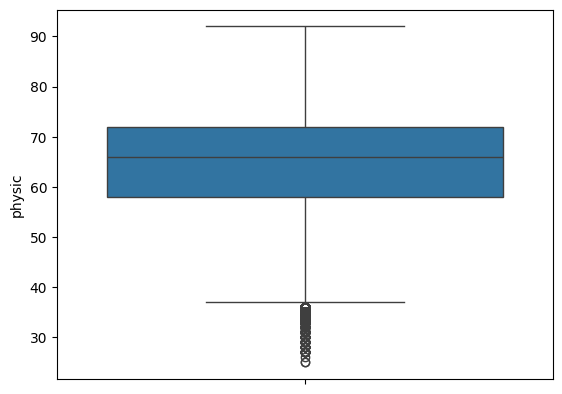

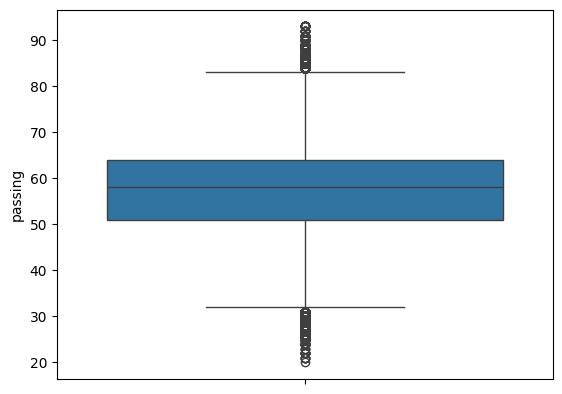

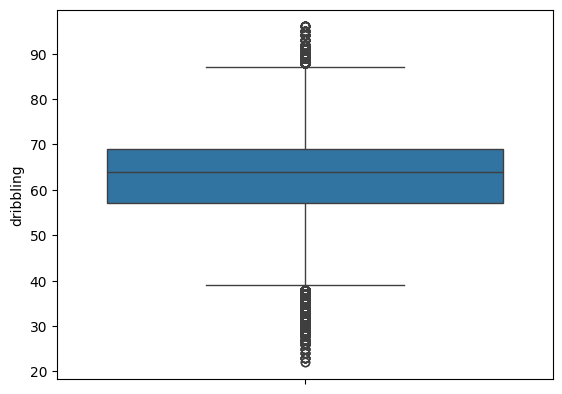

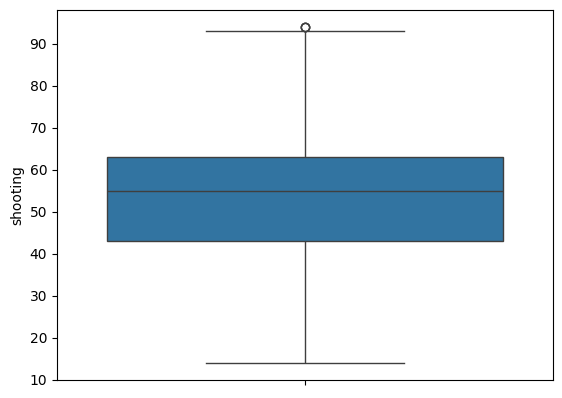

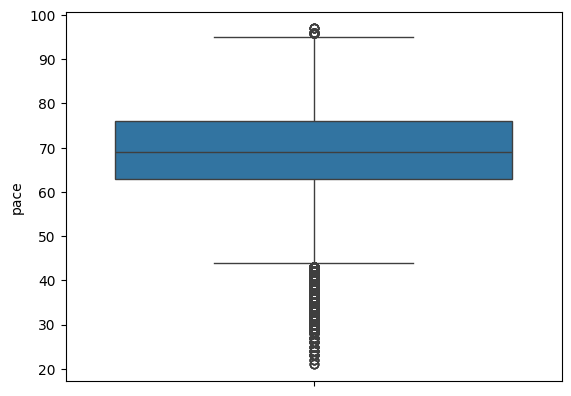

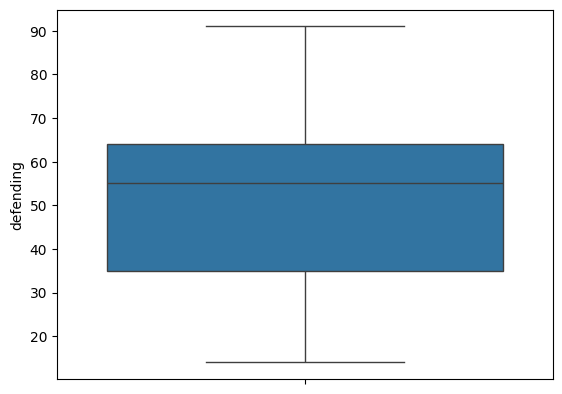

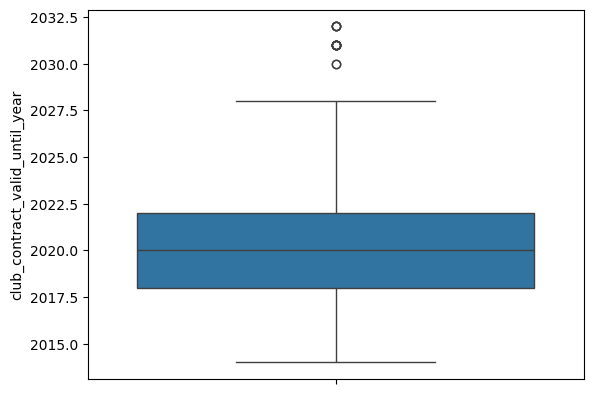

In [20]:
for c in col:
  sns.boxplot(df[c])
  plt.show()

# **Save_data_to_use_in_Unsupervised_model**

In [21]:
df.to_csv('clean_data.csv',index=False)
#when work on unsupervised.....................

# **modifiing_player_position_that have 2 values**

In [22]:
df['player_positions'] = df['player_positions'].str.split(',').str[0] #because of player that have 2 position play we choose the first position

df['player_positions'] = df['player_positions'].str.strip() # to drop the free space if it waas

df.head()
df['player_positions'].value_counts()

,count
player_positions,
CB,121855
ST,112868
CM,91132
CDM,59253
RB,54292
LB,53927
CAM,48222
RM,46875
LM,46485


# **Visualization**

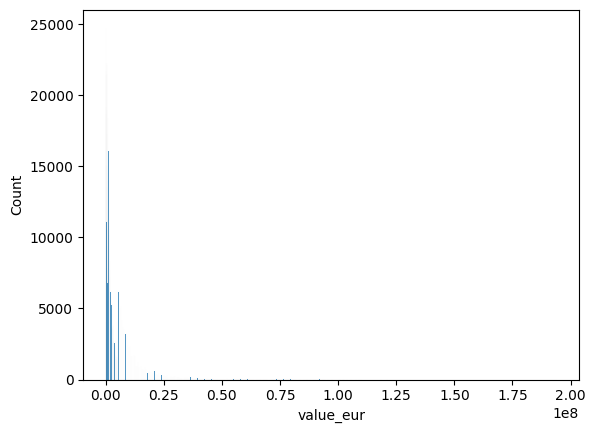

In [23]:
sns.histplot(df['value_eur'])
plt.show()


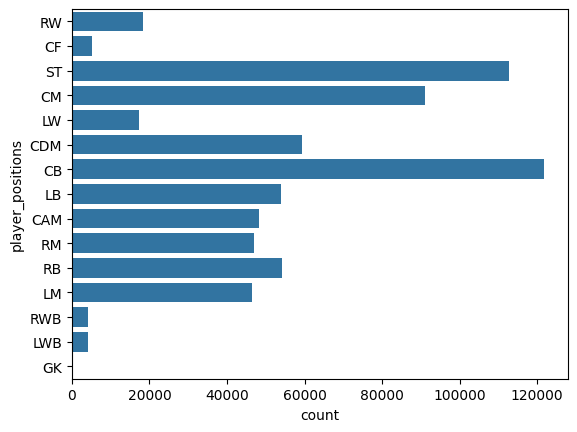

In [24]:
sns.countplot(df['player_positions'])
plt.show()

# **encoding Catogorical_columns**

In [25]:
from sklearn.preprocessing import OneHotEncoder

ohn=OneHotEncoder()
df = pd.get_dummies(df, columns=['preferred_foot','player_positions'], drop_first=True)

cols_to_drop = ['short_name', 'club_name']
df = df.drop(cols_to_drop, axis=1)
df.head()




,overall,potential,value_eur,wage_eur,age,height_cm,club_contract_valid_until_year,pace,shooting,passing,...,player_positions_GK,player_positions_LB,player_positions_LM,player_positions_LW,player_positions_LWB,player_positions_RB,player_positions_RM,player_positions_RW,player_positions_RWB,player_positions_ST
0,91,91,54000000.0,195000.0,35,169,2023.0,81.0,89.0,90.0,...,False,False,False,False,False,False,False,True,False,False
1,91,91,64000000.0,450000.0,34,185,2023.0,80.0,88.0,83.0,...,False,False,False,False,False,False,False,False,False,False
2,91,91,84000000.0,420000.0,33,185,2025.0,75.0,91.0,79.0,...,False,False,False,False,False,False,False,False,False,True
3,91,91,107500000.0,350000.0,31,181,2025.0,74.0,88.0,93.0,...,False,False,False,False,False,False,False,False,False,False
4,91,95,190500000.0,230000.0,23,182,2024.0,97.0,89.0,80.0,...,False,False,False,False,False,False,False,False,False,True


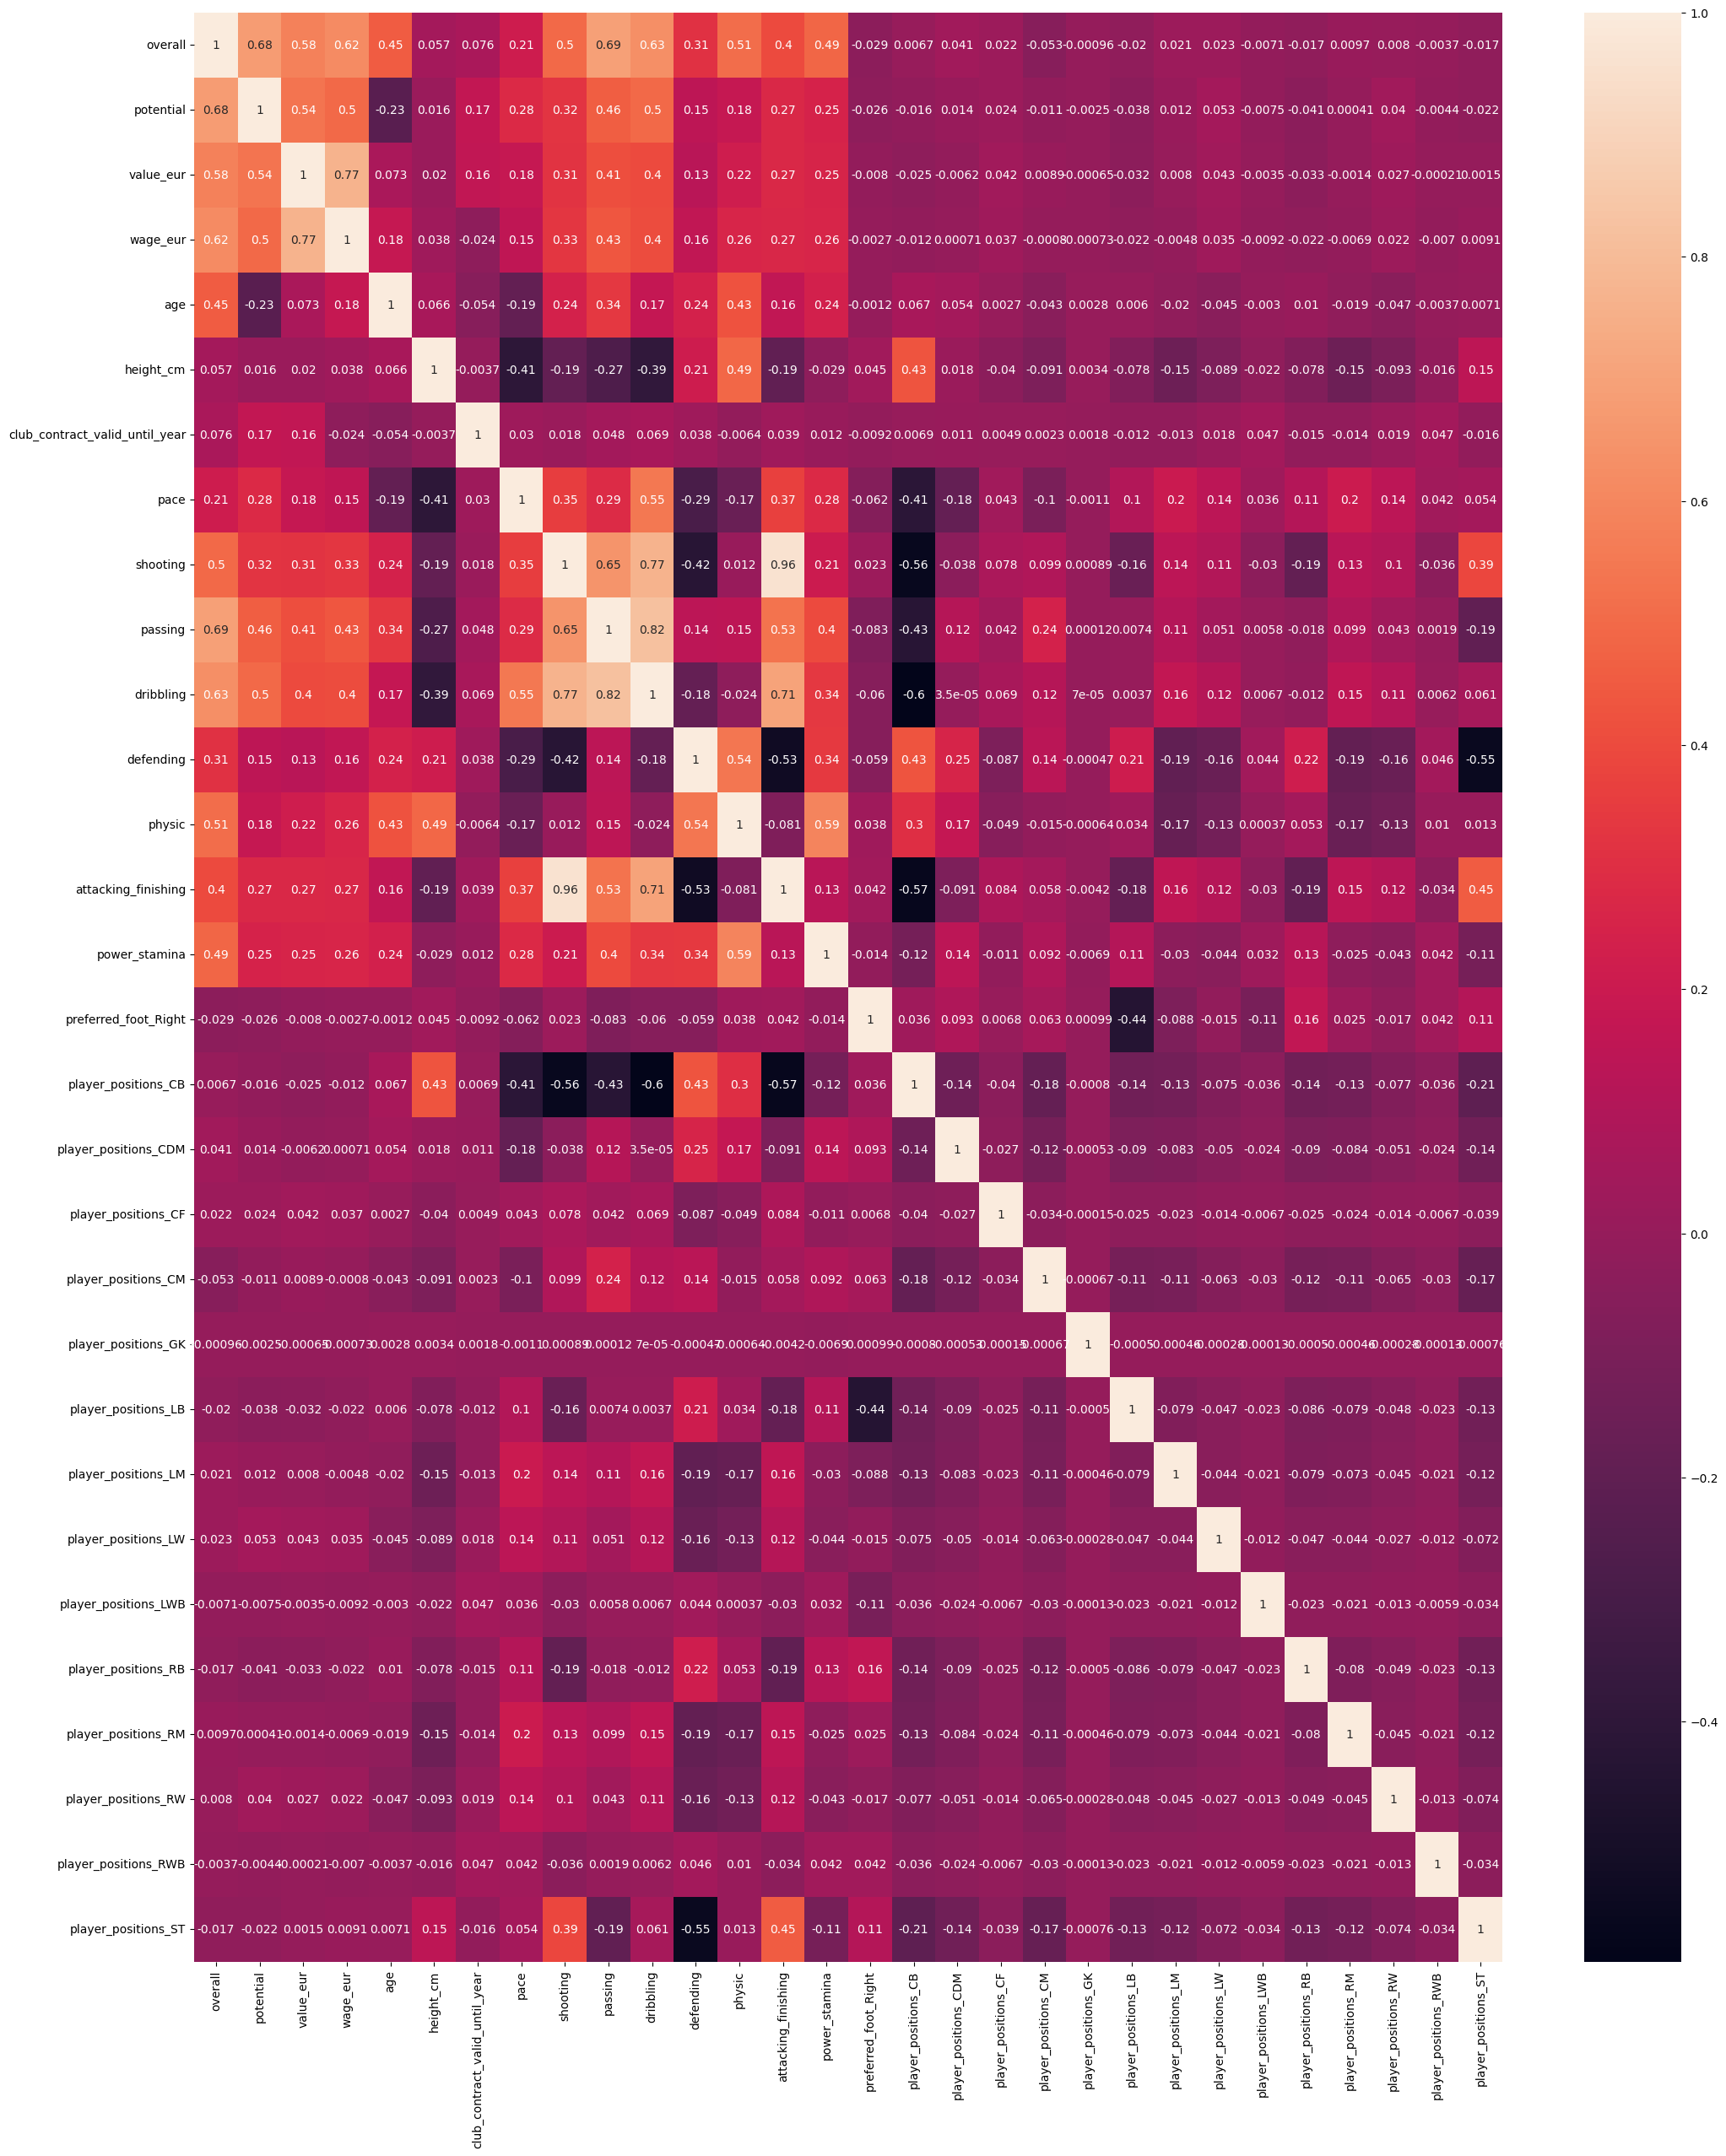

In [26]:
plt.figure(figsize=(25, 30))
sns.heatmap(df.corr(), annot=True)
plt.show()

# **Split ELdata**

In [27]:
X=df.drop('value_eur',axis=1)
y=df['value_eur']

# **Cross Validation**

In [28]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=42)

kfold = KFold(n_splits=5, shuffle=True, random_state=42)


cv_results = cross_val_score(model, X, y, cv=kfold, scoring='r2')

print("R2 Scores for the 5 folds:", cv_results)
print("Average R2 Score (The Real Accuracy):", cv_results.mean())

R2 Scores for the 5 folds: [0.98929484 0.99067639 0.98984591 0.98768042 0.98942704]
Average R2 Score (The Real Accuracy): 0.989384920385443


# **Train_test_split**

In [29]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# **Scaling**

In [30]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

# **model Linear Regression**

In [31]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,y_train)

LinearRegression()

In [32]:
y_predict=model.predict(X_test)

# **Metrics**

In [33]:
r2_score(y_test,y_predict)


0.6570964483514106

In [34]:
from sklearn.model_selection import GridSearchCV

# **Random Forest reggrisor**

In [35]:
from sklearn.ensemble import RandomForestRegressor
model=RandomForestRegressor()
model.fit(X_train,y_train)

RandomForestRegressor()

In [36]:
y_predict=model.predict(X_test)

In [37]:
r2_score(y_test,y_predict)

0.9895338098992079

# **Split_Rating**

In [38]:
x_rat = df.drop(
    columns=['overall', 'value_eur']
)

y_rat = df['overall']

In [39]:
x_rat_train,x_rat_test,y_rat_train,y_rat_test=train_test_split(x_rat,y_rat,test_size=0.2,random_state=42)

# **XG_boost**

In [40]:
from xgboost import XGBRegressor
model_xg=XGBRegressor(random_state=42)

model_xg.fit(x_rat_train,y_rat_train)
y_rat_predict=model_xg.predict(x_rat_test)
r2_score(y_rat_test,y_rat_predict)


0.9838560223579407

In [41]:
y_rat_train_predict = model_xg.predict(x_rat_train)
y_rat_test_predict = model_xg.predict(x_rat_test)

print("Training R2:", r2_score(y_rat_train, y_rat_train_predict))
print("Test R2:", r2_score(y_rat_test, y_rat_test_predict))

Training R2: 0.9842813014984131
Test R2: 0.9838560223579407


In [42]:
from sklearn.model_selection import KFold, cross_val_score

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_val_score(
    model_xg,
    x_rat,
    y_rat,
    cv=kfold,
    scoring='r2',
    n_jobs=-1
)

print("R2 Scores for the 5 folds:", cv_results)
print("Average CV R2:", cv_results.mean())
print("Standard Deviation:", cv_results.std())

R2 Scores for the 5 folds: [0.98385602 0.98352659 0.98351866 0.98366755 0.98362142]
Average CV R2: 0.9836380481719971
Standard Deviation: 0.000122749175076303


In [53]:
import html as _h
import pandas as pd
import ipywidgets as w
from IPython.display import display, HTML, clear_output

POS = sorted(["CAM"] + [c.replace("player_positions_", "") for c in x_rat.columns if c.startswith("player_positions_")])

def _row(cols, vals, pos, foot):
    r = pd.DataFrame([[0.0] * len(cols)], columns=cols)
    for k, v in vals.items():
        if k in r.columns: r.at[0, k] = float(v)
    if f"player_positions_{pos}" in r.columns: r.at[0, f"player_positions_{pos}"] = 1.0
    if foot == "Right" and "preferred_foot_Right" in r.columns: r.at[0, "preferred_foot_Right"] = 1.0
    return r

def _money(v):
    return f"€{v/1e6:.1f}M" if v >= 1e6 else (f"€{v/1e3:.0f}K" if v >= 1e3 else f"€{v:.0f}")

def _tier(r):
    return "elite" if r >= 86 else "gold" if r >= 75 else "silver" if r >= 65 else "bronze"

CSS = """<style>
.fc{--a:#f7e7a1;--b:#d4af37;--c:#8a6d1b;--ink:#3a2c05;position:relative;width:310px;height:450px;margin:10px auto;color:var(--ink);
background:linear-gradient(155deg,var(--a),var(--b) 55%,var(--c));font-family:'Arial Narrow',Arial,sans-serif;
clip-path:polygon(50% 0,92% 6%,100% 12%,100% 86%,50% 100%,0 86%,0 12%,8% 6%)}
.fc.silver{--a:#f2f4f7;--b:#b5bcc7;--c:#6b7480;--ink:#1e2530}.fc.bronze{--a:#f0c9a0;--b:#c27c3f;--c:#74411a;--ink:#2e1805}
.fc.elite{--a:#7cf5ff;--b:#2a5bd7;--c:#1a1250;--ink:#fff}
.fc .l{position:absolute;left:34px;top:52px;text-align:center;width:60px}.fc .r{font-size:56px;font-weight:700;line-height:1}
.fc .p{font-size:22px;font-weight:700}.fc .s{height:2px;background:currentColor;opacity:.35;margin:8px 10px}.fc .f{font-size:13px;font-weight:700}
.fc svg{position:absolute;right:30px;top:40px;width:170px;height:170px;opacity:.85}
.fc .n{position:absolute;top:228px;left:0;right:0;text-align:center;font-size:26px;font-weight:700;letter-spacing:1.5px;text-transform:uppercase;padding:0 30px;white-space:nowrap;overflow:hidden}
.fc .ln{position:absolute;top:268px;left:50px;right:50px;height:2px;background:currentColor;opacity:.35}
.fc .g{position:absolute;top:278px;left:0;right:0;display:grid;grid-template-columns:1fr 1fr;padding:0 52px}
.fc .g div{font-size:21px;font-weight:600;text-align:center}.fc .g b{margin-right:8px}.fc .g span{opacity:.75}
.fc .v{position:absolute;bottom:34px;left:0;right:0;text-align:center}.fc .v small{display:block;font-size:11px;letter-spacing:3px;opacity:.75}.fc .v div{font-size:30px;font-weight:700}
</style>"""

def card(name, ovr, val, pos, foot, st):
    g = "".join(f"<div><b>{st[k]}</b><span>{l}</span></div>" for l, k in
                [("PAC","pace"),("DRI","dribbling"),("SHO","shooting"),("DEF","defending"),("PAS","passing"),("PHY","physic")])
    return (CSS + f'<div class="fc {_tier(ovr)}"><div class="l"><div class="r">{ovr}</div><div class="p">{pos}</div>'
            f'<div class="s"></div><div class="f">{foot.upper()}</div></div>'
            '<svg viewBox="0 0 100 100" fill="currentColor"><circle cx="50" cy="32" r="18"/><path d="M12 100c0-26 16-40 38-40s38 14 38 40z"/></svg>'
            f'<div class="n">{_h.escape(name or "PLAYER")}</div><div class="ln"></div><div class="g">{g}</div>'
            f'<div class="v"><small>MARKET VALUE</small><div>{_money(val)}</div></div></div>')

def S(label, v, lo=1, hi=99):
    return w.IntSlider(value=v, min=lo, max=hi, description=label, style={"description_width": "90px"}, layout=w.Layout(width="360px"))

name = w.Text(value="Your Player", description="Name", style={"description_width": "90px"})
pos = w.Dropdown(options=POS, value="ST" if "ST" in POS else POS[0], description="Position", style={"description_width": "90px"})
foot = w.ToggleButtons(options=["Right", "Left"], description="Foot", style={"description_width": "90px"})
age, pot = S("Age", 24, 15, 45), S("Potential", 80, 40, 95)
wage = w.IntText(value=20000, description="Wage €/wk", style={"description_width": "90px"})
contract = S("Contract", 2026, 2023, 2030)
height = S("Height cm", 180, 150, 210)
pace, sho, pas, dri, dfn, phy, sta, fin = (S("Pace", 75), S("Shooting", 75), S("Passing", 70), S("Dribbling", 75),
                                          S("Defending", 40), S("Physical", 70), S("Stamina", 70), S("Finishing", 75))
btn = w.Button(description="Predict", button_style="success", icon="futbol-o")
out = w.Output()

def go(_):
    v = dict(age=age.value, potential=pot.value, wage_eur=wage.value, club_contract_valid_until_year=contract.value,
             height_cm=height.value, pace=pace.value, shooting=sho.value, passing=pas.value, dribbling=dri.value,
             defending=dfn.value, physic=phy.value, power_stamina=sta.value, attacking_finishing=fin.value)
    ovr = int(round(min(99, max(1, float(model_xg.predict(_row(x_rat.columns, v, pos.value, foot.value))[0])))))
    val = max(0.0, float(model.predict(scaler.transform(_row(X.columns, {**v, "overall": ovr}, pos.value, foot.value)))[0]))
    with out:
        clear_output(wait=True)
        display(HTML(card(name.value, ovr, val, pos.value, foot.value, v)))

btn.on_click(go)
form = w.VBox([name, pos, foot, age, height, pot, wage, contract, pace, sho, pas, dri, dfn, phy, sta, fin, btn])
display(w.HBox([form, out]))
go(None)

In [54]:
import joblib, json
joblib.dump({"model": model, "scaler": scaler}, "value_model.pkl", compress=3)
model_xg.save_model("rating_model.json")
json.dump({"rating_cols": list(x_rat.columns), "value_cols": list(X.columns)}, open("meta.json", "w"))

!pip install -q streamlit
from google.colab import files
files.upload()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 107.5 MB/s eta 0:00:00


Saving app.py to app.py


{'app.py': b'import html as _html\nimport json\n\nimport joblib\nimport pandas as pd\nimport streamlit as st\nimport streamlit.components.v1 as components\nfrom xgboost import XGBRegressor\n\nst.set_page_config(page_title="FIFA 23 Card Predictor", page_icon="\xe2\x9a\xbd", layout="wide")\n\n\n@st.cache_resource\ndef load_artifacts():\n    rating_model = XGBRegressor()\n    rating_model.load_model("rating_model.json")\n    bundle = joblib.load("value_model.pkl")\n    with open("meta.json") as f:\n        meta = json.load(f)\n    return rating_model, bundle["model"], bundle["scaler"], meta\n\n\nrating_model, value_model, scaler, meta = load_artifacts()\nRATING_COLS, VALUE_COLS = meta["rating_cols"], meta["value_cols"]\n\n# get_dummies(drop_first=True) dropped the alphabetically-first position (CAM)\nPOSITIONS = sorted(\n    ["CAM"] + [c.replace("player_positions_", "") for c in RATING_COLS if c.startswith("player_positions_")]\n)\n\n\ndef build_row(cols, values, position, foot):\n    row

In [55]:
import subprocess, time, re

subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

log = open("cf.log", "w")
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"], stdout=log, stderr=log)

for _ in range(40):
    time.sleep(1)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cf.log").read())
    if m:
        print(m.group(0))
        break

https://plasma-listed-mineral-wilderness.trycloudflare.com
